# TabMmini final artifact review

Read-only review of the published TabMmini evidence. This notebook does not train, fit, transform, select a threshold, run inference, publish artifacts, or create `FROZEN`.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

RUN_ID = 'tabmmini_final_15f_20261004_01'
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'artifacts' / 'dataset_b').is_dir())
FINAL_ROOT = PROJECT_ROOT / 'artifacts' / 'dataset_b' / 'tabmmini' / 'final' / RUN_ID
REPORTING_ROOT = FINAL_ROOT / 'reporting'

In [2]:
model_summary = json.loads((REPORTING_ROOT / 'model_summary.json').read_text(encoding='utf-8'))
final_review = json.loads((FINAL_ROOT / 'final_review.json').read_text(encoding='utf-8'))
post_move = json.loads((FINAL_ROOT / 'post_move_validation.json').read_text(encoding='utf-8'))
assert model_summary['reporting_status'] == 'COMPLETE'
assert final_review['status'] == 'PASS'
assert post_move['status'] == 'PASS'
display(Markdown(
    f"**PASS:** run `{RUN_ID}` passed direct review and post-move validation. "
    f"Five-fold OOF ROC-AUC is **{model_summary['cv']['mean_roc_auc']:.4f} ± {model_summary['cv']['std_roc_auc']:.4f}**; "
    f"the locked Validation threshold is **{model_summary['validation']['threshold']:.3f}**; "
    f"Test ROC-AUC is **{model_summary['test']['point_metrics']['roc_auc_approved']:.4f}** and balanced accuracy is **{model_summary['test']['point_metrics']['balanced_accuracy']:.4f}**."
))

**PASS:** run `tabmmini_final_15f_20261004_01` passed direct review and post-move validation. Five-fold OOF ROC-AUC is **0.8572 ± 0.0017**; the locked Validation threshold is **0.508**; Test ROC-AUC is **0.8578** and balanced accuracy is **0.7799**.

## Cross-validation and RQ1 metrics

In [3]:
cv_metrics = pd.read_csv(REPORTING_ROOT / 'cv_fold_metrics.csv')
rq1_metrics = pd.read_csv(REPORTING_ROOT / 'rq1_metrics_long.csv')
display(cv_metrics[['fold', 'roc_auc', 'fit_seconds']].round(4))
display(rq1_metrics[['metric', 'estimate', 'ci_low', 'ci_high', 'valid_replicates']].round(4))

,fold,roc_auc,fit_seconds
0,1,0.8560,281.0282
1,2,0.8571,286.6498
2,3,0.8589,283.9550
3,4,0.8546,288.6296
4,5,0.8592,283.9396


,metric,estimate,ci_low,ci_high,valid_replicates
0,roc_auc_approved,0.8578,0.8533,0.8618,1000
1,average_precision_denied,0.7742,0.7679,0.7799,1000
2,precision_denied,0.6435,0.6363,0.6501,1000
3,recall_denied,0.6902,0.6820,0.6980,1000
4,f1_denied,0.6660,0.6596,0.6724,1000
5,recall_approved,0.8697,0.8659,0.8731,1000
6,balanced_accuracy,0.7799,0.7754,0.7844,1000
7,brier_score_approved,0.1317,0.1302,0.1333,1000
8,calibration_intercept,0.9982,0.9799,1.0158,1000
9,calibration_slope,0.9976,0.9747,1.0211,1000


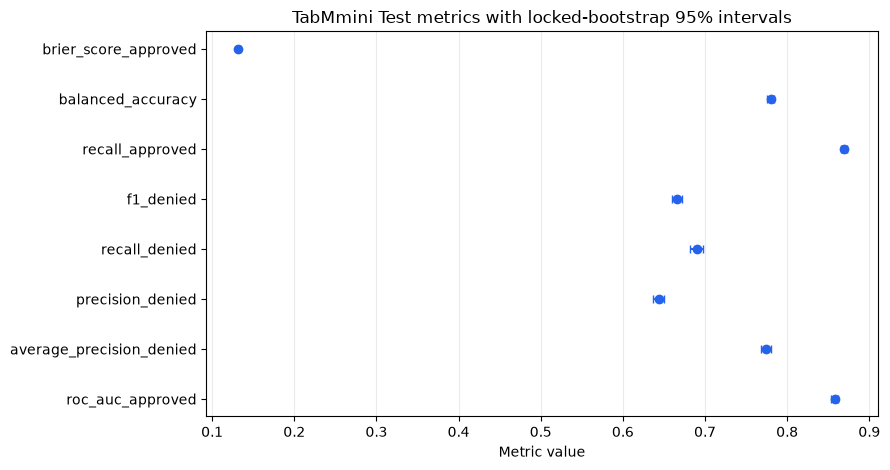

In [4]:
plot_metrics = rq1_metrics[~rq1_metrics['metric'].str.startswith('calibration_')].copy()
plot_metrics['lower_error'] = plot_metrics['estimate'] - plot_metrics['ci_low']
plot_metrics['upper_error'] = plot_metrics['ci_high'] - plot_metrics['estimate']
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.errorbar(plot_metrics['estimate'], plot_metrics['metric'], xerr=[plot_metrics['lower_error'], plot_metrics['upper_error']], fmt='o', capsize=3, color='#2563eb')
ax.set_title('TabMmini Test metrics with locked-bootstrap 95% intervals')
ax.set_xlabel('Metric value')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## Calibration and confusion counts

,model_key,run_id,actual_class,predicted_class,count
0,tabmmini,tabmmini_final_15f_20261004_01,approved,approved,28539
1,tabmmini,tabmmini_final_15f_20261004_01,approved,denied,4276
2,tabmmini,tabmmini_final_15f_20261004_01,denied,approved,3464
3,tabmmini,tabmmini_final_15f_20261004_01,denied,denied,7717


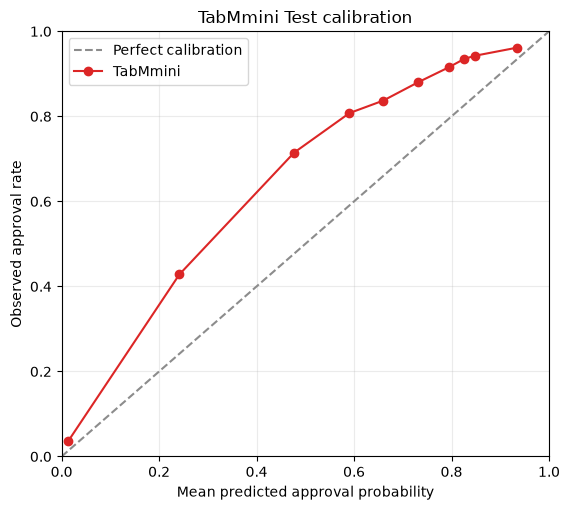

In [5]:
confusion_matrix = pd.read_csv(REPORTING_ROOT / 'confusion_matrix.csv')
calibration_curve = pd.read_csv(REPORTING_ROOT / 'calibration_curve.csv')
display(confusion_matrix)
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, 1], [0, 1], '--', color='0.55', label='Perfect calibration')
ax.plot(calibration_curve['mean_p_approved'], calibration_curve['observed_approval_rate'], marker='o', color='#dc2626', label='TabMmini')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted approval probability', ylabel='Observed approval rate', title='TabMmini Test calibration')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()